# Relative Rotation Graph (RRG)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots each sector's relative strength against a benchmark (x, RS-ratio) and the momentum of that relative strength (y, RS-momentum), with a short tail of recent weeks. Sectors tend to rotate clockwise through four quadrants (improving, leading, weakening, lagging), so the chart shows both where each one is and where it is heading.

## When to use

- Compare sector or asset-class leadership relative to a benchmark
- See which groups are gaining or losing relative momentum before the trend is obvious
- Use as a sector-rotation dashboard for weekly reviews

## Avoid when

- The audience is unfamiliar with relative strength (start with a cumulative relative-return line)
- There are more than ~10 series (tails become spaghetti)
- Presenting it as a timing signal; it describes past relative performance and does not forecast

## Alternatives

- Relative performance lines indexed to 100
- Ranking table of trailing returns
- Bump chart of sector ranks

## Design tips

- Keep tails short (5–10 periods) and mark the latest point clearly
- Label each head directly; color is not needed when position and label identify the series
- Tint the quadrants lightly and name them; the quadrant is the message
- Explain the normalisation used. The original JdK RS-Ratio formula is proprietary, and this example uses a transparent EMA-based approximation

## Example

104 weeks of six simulated sector indices against a simulated benchmark (illustrative). RS-ratio = 100 × fast/slow EMA of relative strength; RS-momentum = 100 × RS-ratio / its value 3 weeks ago.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(5)
weeks = 104
dates = pd.date_range("2024-01-05", periods=weeks, freq="W-FRI")
t = np.arange(weeks)
bench = 100 * np.exp(np.cumsum(rng.normal(0.002, 0.02, weeks)))
sectors = ["Technology", "Financials", "Health care", "Energy", "Utilities", "Industrials"]
phases = np.linspace(0, 2 * np.pi, len(sectors), endpoint=False)
prices = pd.DataFrame({
    s: bench * np.exp(0.07 * np.sin(2 * np.pi * t / 40 + ph) + np.cumsum(rng.normal(0, 0.004, weeks)))
    for s, ph in zip(sectors, phases)}, index=dates)

rs = prices.div(bench, axis=0)                                   # relative strength
rs_ratio = 100 * rs.ewm(span=6).mean() / rs.ewm(span=26).mean()  # trend of RS
rs_mom = 100 * rs_ratio / rs_ratio.shift(3)                      # rate of change of that trend
rs_ratio.tail(3).round(2)

,Technology,Financials,Health care,Energy,Utilities,Industrials
2025-12-12,98.81,95.70,97.77,100.35,104.70,103.33
2025-12-19,98.17,95.72,98.24,101.04,104.78,102.88
2025-12-26,97.64,95.70,98.87,101.66,104.76,102.35


### Plot

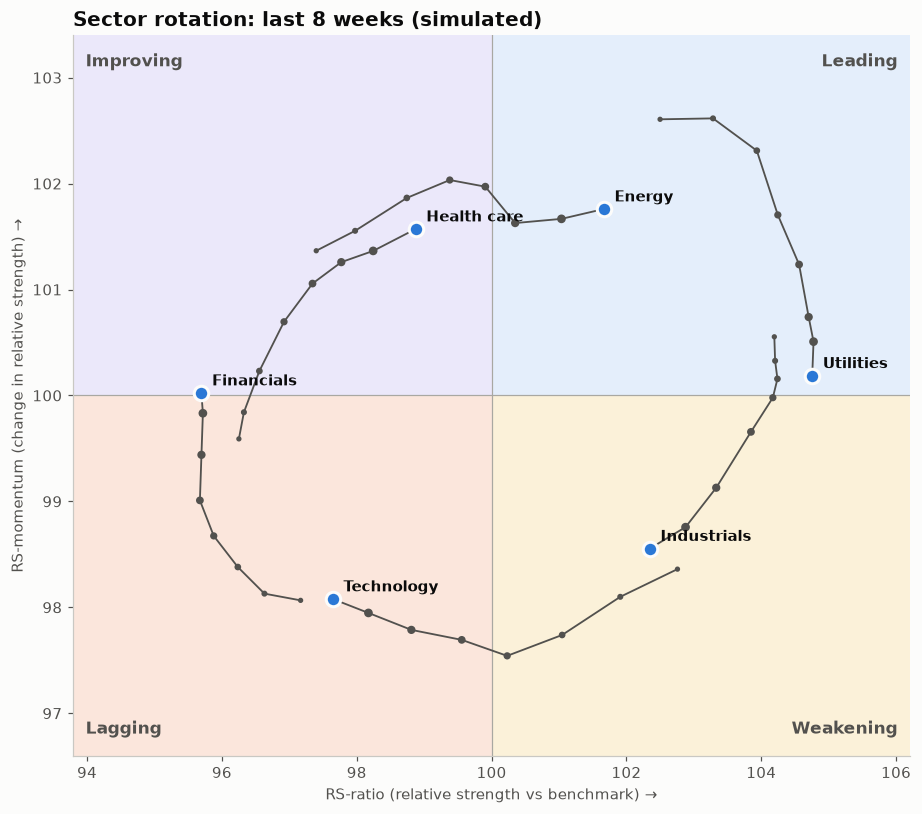

In [3]:
tail = 8
r, m = rs_ratio.iloc[-tail:], rs_mom.iloc[-tail:]
dx = (r - 100).abs().to_numpy().max() * 1.3
dy = (m - 100).abs().to_numpy().max() * 1.3

fig, ax = plt.subplots(figsize=(8.5, 7.5))
quads = [((100, 100), "Leading", "#e4eefb", (1, 1)), ((100 - dx, 100), "Improving", "#ebe8fa", (-1, 1)),
         ((100 - dx, 100 - dy), "Lagging", "#fbe6dc", (-1, -1)), ((100, 100 - dy), "Weakening", "#fbf1d9", (1, -1))]
for (x0, y0), name, tint, (sx, sy) in quads:
    ax.add_patch(plt.Rectangle((x0, y0), dx, dy, facecolor=tint, linewidth=0, zorder=0))
    ax.text(100 + sx * dx * 0.97, 100 + sy * dy * 0.95, name, ha="right" if sx > 0 else "left",
            va="top" if sy > 0 else "bottom", fontsize=11, fontweight="bold", color="#52514e")
ax.axhline(100, color="#a9a8a2", linewidth=0.8)
ax.axvline(100, color="#a9a8a2", linewidth=0.8)

for s in sectors:
    ax.plot(r[s], m[s], color="#52514e", linewidth=1.2, zorder=2)
    ax.scatter(r[s].iloc[:-1], m[s].iloc[:-1], s=np.linspace(6, 22, tail - 1), color="#52514e", zorder=3)
    ax.scatter(r[s].iloc[-1], m[s].iloc[-1], s=90, color=PALETTE[0], edgecolor="#fcfcfb",
               linewidth=2, zorder=4)
    ax.annotate(s, (r[s].iloc[-1], m[s].iloc[-1]), xytext=(7, 5), textcoords="offset points",
                fontsize=9.5, fontweight="bold", zorder=5)

ax.set_xlim(100 - dx, 100 + dx)
ax.set_ylim(100 - dy, 100 + dy)
ax.grid(False)
ax.set_xlabel("RS-ratio (relative strength vs benchmark) →")
ax.set_ylabel("RS-momentum (change in relative strength) →")
ax.set_title(f"Sector rotation: last {tail} weeks (simulated)")
fig.tight_layout()
plt.show()

## How to read it

Right of 100 means the sector is outperforming the benchmark, and above 100 means that outperformance is accelerating. Follow each tail to its dot: most sectors move clockwise, from Improving to Leading to Weakening to Lagging.

---
Standalone script: [`relative_rotation_graph.py`](relative_rotation_graph.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)